In [1]:
!pip install gymnasium==1.2.0

  Using cached Farama_Notifications-0.0.4-py3-none-any.whl.metadata (558 bytes)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 944.3/944.3 kB 26.6 MB/s eta 0:00:00
Using cached Farama_Notifications-0.0.4-py3-none-any.whl (2.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [gymnasium]/3 [gymnasium]


In [3]:
import numpy as np
if not hasattr(np, "bool8"):
    np.bool8 = np.bool_
import gymnasium as gym

In [4]:
print(gym.__version__)

1.2.0


In [5]:
#env = TimeLimit(gym.make("Taxi-v3", render_mode="ansi", is_rainy=True, fickle_passenger=True), max_episode_steps=200)
env = gym.make("Taxi-v3", render_mode="ansi", is_rainy=True, fickle_passenger=True)
P = env.unwrapped.P

# Inspect a few transitions to confirm non-determinism
for s in list(P.keys())[:3]:
    print(f"State {s}:")
    for a, trans in P[s].items():
        print(f"  Action {a}: {trans}")

State 0:
  Action 0: [(0.8, 100, -1, False), (0.1, 0, -1, False), (0.1, 20, -1, False)]
  Action 1: [(0.8, 0, -1, False), (0.1, 0, -1, False), (0.1, 20, -1, False)]
  Action 2: [(0.8, 20, -1, False), (0.1, 100, -1, False), (0.1, 0, -1, False)]
  Action 3: [(0.8, 0, -1, False), (0.1, 0, -1, False), (0.1, 0, -1, False)]
  Action 4: [(1.0, 16, -1, False)]
  Action 5: [(1.0, 0, -10, False)]
State 1:
  Action 0: [(0.8, 101, -1, False), (0.1, 1, -1, False), (0.1, 21, -1, False)]
  Action 1: [(0.8, 1, -1, False), (0.1, 1, -1, False), (0.1, 21, -1, False)]
  Action 2: [(0.8, 21, -1, False), (0.1, 101, -1, False), (0.1, 1, -1, False)]
  Action 3: [(0.8, 1, -1, False), (0.1, 1, -1, False), (0.1, 1, -1, False)]
  Action 4: [(1.0, 17, -1, False)]
  Action 5: [(1.0, 1, -10, False)]
State 2:
  Action 0: [(0.8, 102, -1, False), (0.1, 2, -1, False), (0.1, 22, -1, False)]
  Action 1: [(0.8, 2, -1, False), (0.1, 2, -1, False), (0.1, 22, -1, False)]
  Action 2: [(0.8, 22, -1, False), (0.1, 102, -1, False

We will be using OpenAI Gym. In Gym, every environment has a state and action space, accessible via `env.action_space` and `env.observation_space`

The underlying source code for the environment is available at: https://github.com/Farama-Foundation/Gymnasium/blob/main/gymnasium/envs/toy_text/taxi.py

In [6]:
action_size = env.action_space.n
state_size = env.observation_space.n
print(f"Action size: {action_size}")
print(f"State size: {state_size}")

Action size: 6
State size: 500


In [7]:
# action space is represnted by a Discrete object
print(env.action_space)

Discrete(6)


In [8]:
class RandomPolicy:
    def __init__(self, action_size, seed: int ):
        self.action_size = action_size
        self.rng = np.random.default_rng(seed)
        self.state_action = self.rng.integers(low=0, high=action_size, size=(state_size,))


    def get_action(self, state: int) -> int:
        return self.state_action[state]

In [9]:
rand_policies = [RandomPolicy(action_size, seed=i) for i in range(5)]

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

In [27]:
def get_random_trajectory(policy, render=False):
    x0 = 221
    ob, info = env.reset()
    env.unwrapped.s = x0
    ob = x0
    traj_length = 0
    rewards = []
    success = False
    done = False
    while not done:
        action = policy.get_action(ob)
        ob, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        traj_length += 1
        rewards.append(reward)
        success = reward == 20
        if render:
            env.render()
    return rewards, traj_length, success

In [28]:
r, l, success = get_random_trajectory(rand_policies[0], render=False)
print(f"Rewards: {r}")
print(f"Trajectory length: {l}")
print(f"Successful dropoff: {success}")

Rewards: [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
Trajectory length: 200
Successful dropoff: False


In [29]:
gamma = 0.9
nb_rollouts = 100

# Monte Carlo Policy Evaluation

In [30]:
def compute_monte_carlo_value_function_stats(rewards: list, gamma: float):
    print(f"Computing MC value function stats for {len(rewards)} episodes")
    Gs = []
    for i, episode_rewards in enumerate(rewards):
        print(f"length of episode {i+1}: {len(episode_rewards)}")
        G = 0.0
        for r in reversed(episode_rewards):
            G = r + gamma * G
        Gs.append(G)
    mean_discounted_return = np.mean(Gs)
    var_discounted_return = np.var(Gs)
    return mean_discounted_return, var_discounted_return

In [31]:
def compute_monte_carlo_policy_evaluation(num_traj: int, gamma: float, policies: list) -> dict:
    output = {}
    for i, policy in enumerate(policies):
        print(f"Evaluating policy {i+1}/{len(policies)}")
        rewards_all = []
        success_count = 0
        for j in range(num_traj):
            print(f"Traj {j+1}/{num_traj}")
            rewards, _, success = get_random_trajectory(policy=policy, render=False)
            rewards_all.append(rewards)
            success_count += int(success)
        mean_g, var_g = compute_monte_carlo_value_function_stats(rewards_all, gamma=gamma)
        output[f"π_rand_{i+1}"] = {
            "mean": mean_g,
            "var": var_g,
            "success_rate": success_count / num_traj
        }
    return output

In [32]:
mc_stats = compute_monte_carlo_policy_evaluation(num_traj=nb_rollouts, gamma=gamma, policies=rand_policies)

Evaluating policy 1/5
Traj 1/100
Traj 2/100
Traj 3/100
Traj 4/100
Traj 5/100
Traj 6/100
Traj 7/100
Traj 8/100
Traj 9/100
Traj 10/100
Traj 11/100
Traj 12/100
Traj 13/100
Traj 14/100
Traj 15/100
Traj 16/100
Traj 17/100
Traj 18/100
Traj 19/100
Traj 20/100
Traj 21/100
Traj 22/100
Traj 23/100
Traj 24/100
Traj 25/100
Traj 26/100
Traj 27/100
Traj 28/100
Traj 29/100
Traj 30/100
Traj 31/100
Traj 32/100
Traj 33/100
Traj 34/100
Traj 35/100
Traj 36/100
Traj 37/100
Traj 38/100
Traj 39/100
Traj 40/100
Traj 41/100
Traj 42/100
Traj 43/100
Traj 44/100
Traj 45/100
Traj 46/100
Traj 47/100
Traj 48/100
Traj 49/100
Traj 50/100
Traj 51/100
Traj 52/100
Traj 53/100
Traj 54/100
Traj 55/100
Traj 56/100
Traj 57/100
Traj 58/100
Traj 59/100
Traj 60/100
Traj 61/100
Traj 62/100
Traj 63/100
Traj 64/100
Traj 65/100
Traj 66/100
Traj 67/100
Traj 68/100
Traj 69/100
Traj 70/100
Traj 71/100
Traj 72/100
Traj 73/100
Traj 74/100
Traj 75/100
Traj 76/100
Traj 77/100
Traj 78/100
Traj 79/100
Traj 80/100
Traj 81/100
Traj 82/100
Tra

In [33]:
mc_stats

{'π_rand_1': {'mean': np.float64(-9.999999992944923),
  'var': np.float64(0.0),
  'success_rate': 0.0},
 'π_rand_2': {'mean': np.float64(-73.8127160457988),
  'var': np.float64(480.8097215238595),
  'success_rate': 0.0},
 'π_rand_3': {'mean': np.float64(-84.96837904494281),
  'var': np.float64(208.86399653179006),
  'success_rate': 0.0},
 'π_rand_4': {'mean': np.float64(-99.9999999294492),
  'var': np.float64(8.077935669463161e-28),
  'success_rate': 0.0},
 'π_rand_5': {'mean': np.float64(-17.078589986595354),
  'var': np.float64(452.96092781287194),
  'success_rate': 0.0}}

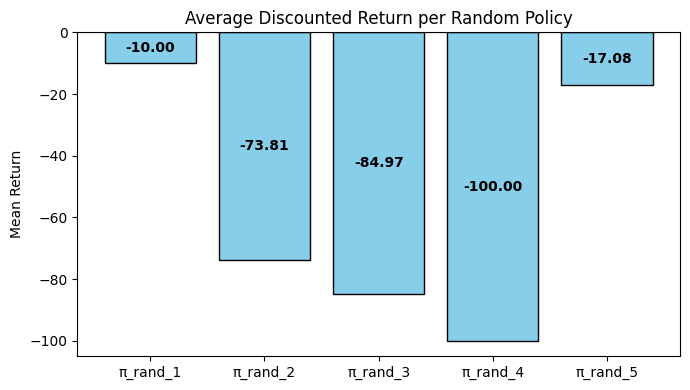

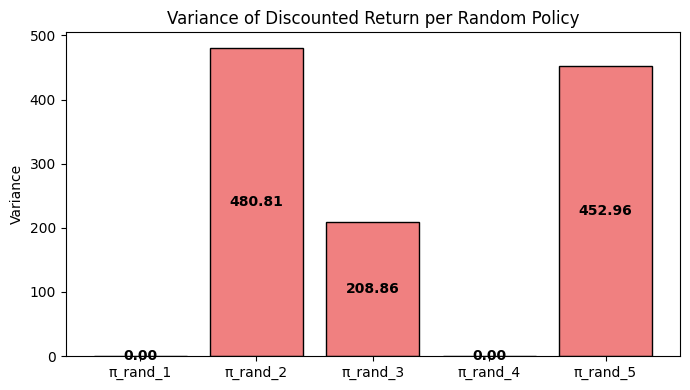

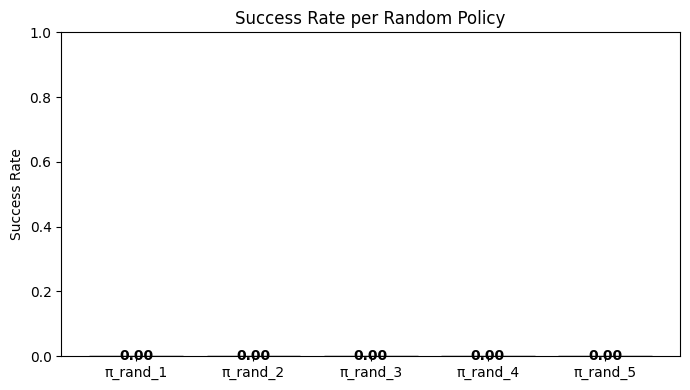

In [ ]:
policies = list(mc_stats.keys())
means = [mc_stats[p]["mean"] for p in policies]
vars_ = [mc_stats[p]["var"] for p in policies]
success = [mc_stats[p]["success_rate"] for p in policies]

def annotate_bars(bars, values, fmt="{:.2f}"):
    for bar, val in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() / 2,
            fmt.format(val),
            ha="center", va="center",
            color="black", fontsize=10, fontweight="bold"
        )

plt.figure(figsize=(7, 4))
bars = plt.bar(policies, means, color="skyblue", edgecolor="black")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Average Discounted Return per Random Policy")
plt.ylabel("Mean Return")
annotate_bars(bars, means)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
bars = plt.bar(policies, vars_, color="lightcoral", edgecolor="black")
plt.title("Variance of Discounted Return per Random Policy")
plt.ylabel("Variance")
annotate_bars(bars, vars_)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
bars = plt.bar(policies, success, color="mediumseagreen", edgecolor="black")
plt.title("Success Rate per Random Policy")
plt.ylabel("Success Rate")
plt.ylim(0, 1)
annotate_bars(bars, success)
plt.tight_layout()
plt.show()

## Discussion 
All five randomly generated deterministic policies perform poorly, as expected,
with negative average returns and a zero success rate.

π_rand_1 and π_rand_4 exhibit almost zero variance,
indicating that their trajectories are highly consistent across episodes.
This could happen when the deterministic policy repeatedly produces similar
transitions and rewards, even though the environment itself may include some
stochastic elements such as random passenger or destination behavior.

π_rand_2, π_rand_3, and π_rand_5 present higher variance, suggesting that there was a mix of moving and doing the wrong action (eg: -10 executing “pickup” and “drop-off” actions illegally). Stochasticity from the transitions in the environment
can lead to more variability in episode outcomes as well. Some trajectories may last longer
or accumulate different penalties before being truncated.

The mean returns, ranging roughly from −10 to −100, reflect
how quickly each policy accumulates negative step rewards.
None of the random deterministic policies manage a successful pickup or dropoff sequence.

Overall, although all policies perform poorly, Monte Carlo evaluation
effectively highlights how different random state–action mappings can result in
distinct performance profiles.

# Value Iteration

To implement value iteration and policy iteration, we need the underlying transition distributions. This is in general not available in Gym environments, but we can access it for Taxi.

`env.env.P` is a dictionary containing the underlying transition and reward dynamics for the environment.

In [ ]:
print(env.unwrapped.P.keys())
transition_dict = env.unwrapped.P

We can view the transition distribution for the initial state. Each key corresponds to an action, and the values give transition probabilities. The possible transitions are specified via tuples representing the probability of the transition, the next state, the reward, and whether the episode terminates.

Actions are 0-indexed and correspond to the following:
    - 0: move south
    - 1: move north
    - 2: move east
    - 3: move west
    - 4: pickup passenger
    - 5: drop off passenger

In [ ]:
init_state = transition_dict[0]
actions = ["South", "North", "East", "West", "Pickup", "Dropoff"]
for k in init_state:
    print(f"action {k}: transitions (p, ns, r, d):  {init_state[k]}")

In [ ]:
# helper function to print policy
def print_policy(policy):
    reshaped_policy = policy.reshape(6,6)
    for i in range(6):
        x = " "
        for j in range(6):
            x += actions[int(reshaped_policy[i][j])]
            if j < 5:
                x += " | "
        print(x)


In [ ]:
policy = np.random.randint(6, size=36)
print("Random policy: ")
print_policy(policy)


We have provided some possible functions and their signatures, though you are certainly free to modify as you see fit.

In [ ]:
def value_iteration(values, gamma, iterations=100, termination=1e-4):
    for _ in range(iterations):
        max_update = 0
        # can make asynchronous updates to values
        for i in range(state_size):
            # ********** TODO ***********
            pass
            # ********** TODO ***********
        # terminate if values don't change much
        if max_update < termination:
            break
    return policy, values

# estimate values
def policy_evaluation(policy, init_values, gamma, termination=1e-4):
    # ********** TODO ***********
    return values

# update actions
def policy_improvement(values, gamma):
    # ********** TODO ***********
    return policy







